In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from ecl.donnees import charger_features, moteur

engine = moteur()
train = charger_features(engine, "train")
test = charger_features(engine, "test")
CIBLE = "defaut_observe"

print("train :", train.shape)
print("test  :", test.shape)
train.head()

train : (30740, 33)
test  : (4886, 33)


,client_id,origine,defaut_observe,type_contrat,montant_credit,annuite,revenu_annuel,prix_bien,taux_effort,age,...,pire_retard_externe_jours,pire_statut_externe_12m,nb_demandes_passees,taux_refus_passe,nb_paiements,pct_paiements_en_retard,retard_paiement_max,nb_echeances_non_payees,utilisation_carte_moyenne,retard_carte_max
0,100015,train,0,Cash loans,148365.0,10678.5,38419.16,135000.0,0.277947,55,...,0.0,0,1,0.000000,0,NaN,NaN,0,NaN,NaN
1,100017,train,0,Cash loans,918468.0,28966.5,225000.00,697500.0,0.128740,38,...,0.0,0,2,0.000000,19,0.000000,0.0,0,NaN,NaN
2,100086,train,0,Cash loans,675000.0,21775.5,135000.00,675000.0,0.161300,39,...,0.0,0,7,0.142857,24,0.000000,0.0,0,0.00000,0.0
3,100110,train,0,Cash loans,373140.0,25065.0,135000.00,337500.0,0.185667,29,...,0.0,0,4,0.000000,7,0.000000,0.0,0,0.00000,0.0
4,100131,train,0,Cash loans,891072.0,45625.5,270000.00,720000.0,0.168983,37,...,0.0,0,2,0.000000,59,0.016949,1.0,0,0.31868,0.0


In [3]:
taux_global = train[CIBLE].mean()
print(f"Clients en difficulté : {train[CIBLE].sum()} sur {len(train)}, soit {taux_global:.2%}")

par_contrat = train.groupby("type_contrat")[CIBLE].agg(clients="count", en_difficulte="sum", taux="mean")
par_contrat

Clients en difficulté : 2441 sur 30740, soit 7.94%


,clients,en_difficulte,taux
type_contrat,,,
Cash loans,27855,2285,0.082032
Revolving loans,2885,156,0.054073


In [4]:
manquants = pd.DataFrame({
    "nb_manquants": train.isna().sum(),
    "pct_manquant": (train.isna().mean() * 100).round(1),
})
manquants = manquants[manquants["nb_manquants"] > 0].sort_values("pct_manquant", ascending=False)
manquants

,nb_manquants,pct_manquant
utilisation_carte_moyenne,22901,74.5
retard_carte_max,22097,71.9
score_externe_1,17353,56.5
score_externe_3,6112,19.9
anciennete_emploi_annees,5590,18.2
pct_paiements_en_retard,5485,17.8
retard_paiement_max,5484,17.8
pire_retard_externe_jours,4414,14.4
taux_refus_passe,1621,5.3
score_externe_2,65,0.2


In [5]:
lignes = []
for col in manquants.index:
    vide = train[col].isna()
    lignes.append({
        "variable": col,
        "taux_si_manquant": train.loc[vide, CIBLE].mean(),
        "taux_si_present": train.loc[~vide, CIBLE].mean(),
    })
signal = pd.DataFrame(lignes).set_index("variable")
signal["ecart_points"] = ((signal["taux_si_manquant"] - signal["taux_si_present"]) * 100).round(2)
signal.round(4)

,taux_si_manquant,taux_si_present,ecart_points
variable,,,
utilisation_carte_moyenne,0.0761,0.0890,-1.29
retard_carte_max,0.0771,0.0854,-0.83
score_externe_1,0.0828,0.0750,0.78
score_externe_3,0.0915,0.0764,1.50
anciennete_emploi_annees,0.0553,0.0848,-2.95
pct_paiements_en_retard,0.0755,0.0803,-0.48
retard_paiement_max,0.0753,0.0803,-0.50
pire_retard_externe_jours,0.0976,0.0764,2.13
taux_refus_passe,0.0605,0.0805,-2.00


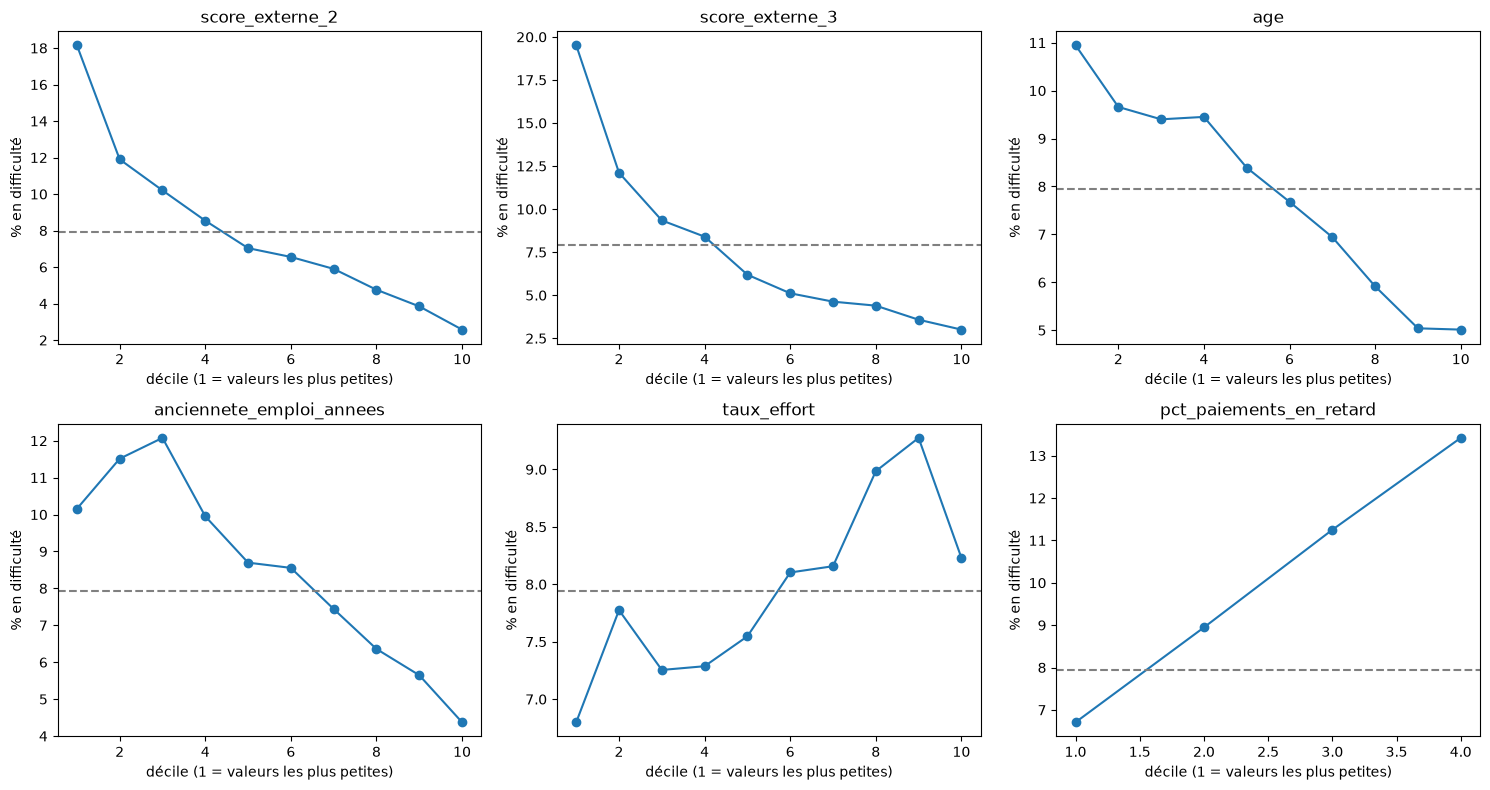

,clients,taux
score_externe_2,,
"(-0.0009999183, 0.213]",3068,0.181551
"(0.213, 0.337]",3067,0.119009
"(0.337, 0.439]",3068,0.102021
"(0.439, 0.513]",3067,0.085425
"(0.513, 0.566]",3069,0.070381
"(0.566, 0.609]",3066,0.065558
"(0.609, 0.646]",3067,0.059015
"(0.646, 0.683]",3068,0.047588
"(0.683, 0.723]",3067,0.038474


In [6]:
import matplotlib.pyplot as plt

def taux_par_decile(df, col):
    deciles = pd.qcut(df[col], 10, duplicates="drop")
    return df.groupby(deciles, observed=True)[CIBLE].agg(clients="count", taux="mean")

variables_cles = ["score_externe_2", "score_externe_3", "age",
                  "anciennete_emploi_annees", "taux_effort", "pct_paiements_en_retard"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, variables_cles):
    t = taux_par_decile(train, col)
    ax.plot(range(1, len(t) + 1), t["taux"] * 100, marker="o")
    ax.axhline(train[CIBLE].mean() * 100, color="grey", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("décile (1 = valeurs les plus petites)")
    ax.set_ylabel("% en difficulté")
plt.tight_layout()
plt.show()

taux_par_decile(train, "score_externe_2")

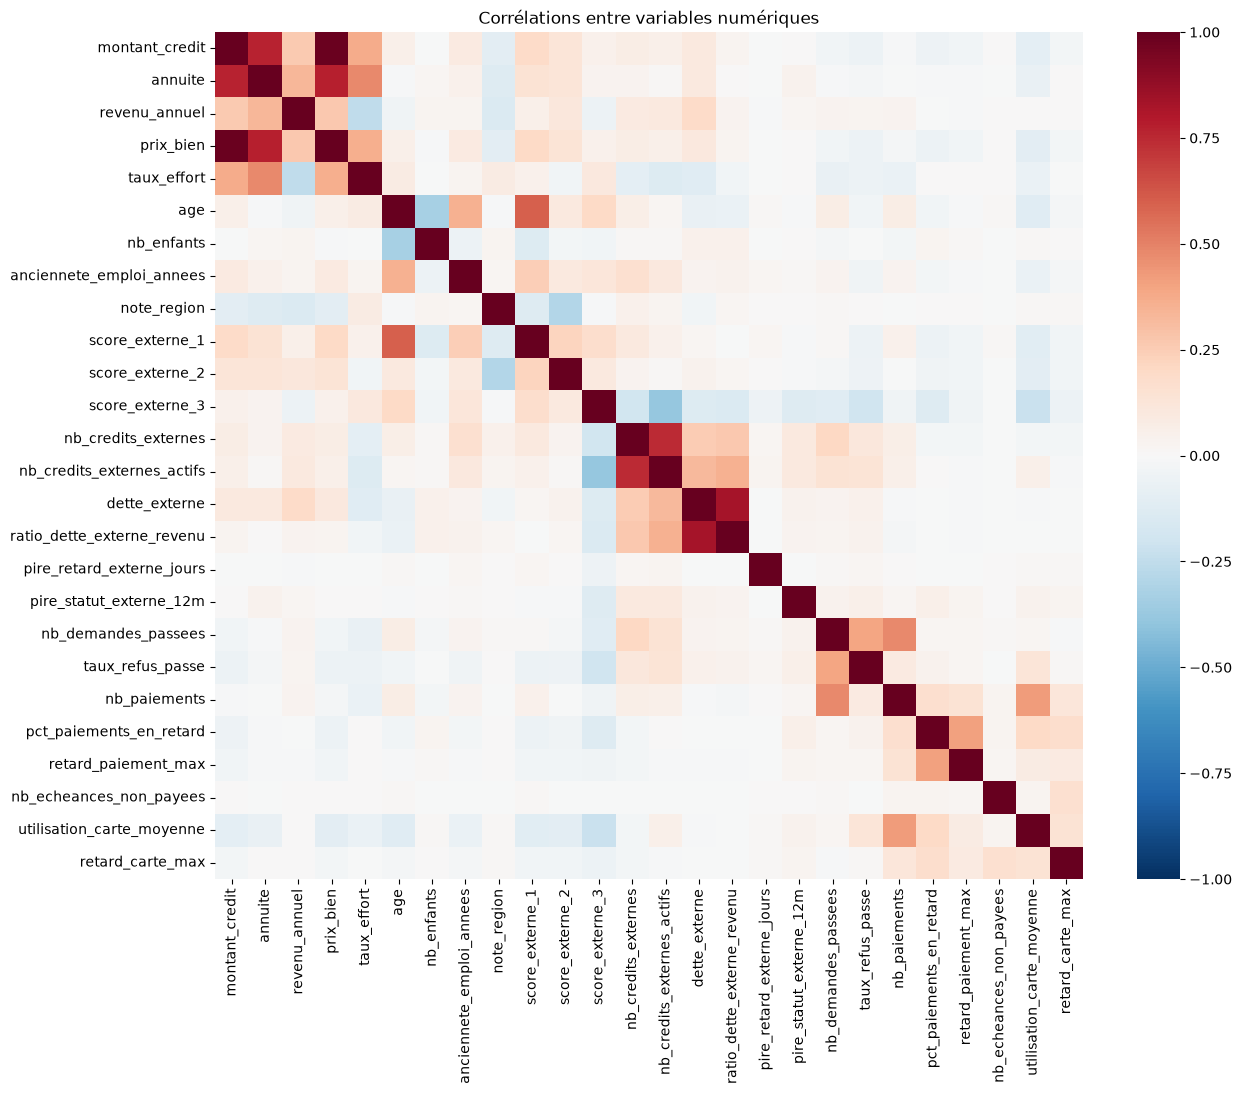

,level_0,level_1,correlation
3,montant_credit,prix_bien,0.986966
379,dette_externe,ratio_dette_externe_revenu,0.833293
29,annuite,prix_bien,0.776942
1,montant_credit,annuite,0.771361
325,nb_credits_externes,nb_credits_externes_actifs,0.744805


In [8]:
import seaborn as sns
import numpy as np
numeriques = train.select_dtypes("number").drop(columns=["client_id", CIBLE])
correlations = numeriques.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(correlations, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Corrélations entre variables numériques")
plt.show()

paires = (correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1))
          .stack().rename("correlation").reset_index())
paires[paires["correlation"].abs() > 0.7].sort_values("correlation", key=abs, ascending=False)

In [11]:
from pandas.api.types import is_bool_dtype, is_numeric_dtype

def psi(reference, actuelle, n_tranches=10):
    reference, actuelle = pd.Series(reference), pd.Series(actuelle)
    if is_numeric_dtype(reference) and not is_bool_dtype(reference):
        bornes = np.unique(reference.quantile(np.linspace(0, 1, n_tranches + 1)).dropna())
        if len(bornes) < 3:
            return np.nan
        bornes[0], bornes[-1] = -np.inf, np.inf
        p_ref = pd.cut(reference, bornes).value_counts(normalize=True, dropna=False)
        p_act = pd.cut(actuelle, bornes).value_counts(normalize=True, dropna=False)
    else:
        p_ref = reference.astype(str).value_counts(normalize=True)
        p_act = actuelle.astype(str).value_counts(normalize=True)
    p_act = p_act.reindex(p_ref.index, fill_value=0)
    p_ref, p_act = p_ref.clip(lower=1e-4), p_act.clip(lower=1e-4)
    return float(((p_act - p_ref) * np.log(p_act / p_ref)).sum())

variables = [c for c in train.columns if c not in ("client_id", "origine", CIBLE)]
stabilite = pd.Series({c: psi(train[c], test[c]) for c in variables}, name="psi")
stabilite.sort_values(ascending=False).round(4).to_frame()

,psi
type_contrat,0.2115
prix_bien,0.0997
score_externe_1,0.0886
montant_credit,0.0802
taux_refus_passe,0.0495
utilisation_carte_moyenne,0.0273
nb_demandes_passees,0.0266
annuite,0.0252
nb_paiements,0.0231
revenu_annuel,0.0170


In [12]:
def psi(reference, actuelle, n_tranches=10):
    reference, actuelle = pd.Series(reference), pd.Series(actuelle)
    if is_numeric_dtype(reference) and not is_bool_dtype(reference):
        bornes = np.unique(reference.quantile(np.linspace(0, 1, n_tranches + 1)).dropna())
        if len(bornes) >= 3:
            bornes[0], bornes[-1] = -np.inf, np.inf
            p_ref = pd.cut(reference, bornes).value_counts(normalize=True, dropna=False)
            p_act = pd.cut(actuelle, bornes).value_counts(normalize=True, dropna=False)
            p_act = p_act.reindex(p_ref.index, fill_value=0)
            p_ref, p_act = p_ref.clip(lower=1e-4), p_act.clip(lower=1e-4)
            return float(((p_act - p_ref) * np.log(p_act / p_ref)).sum())
    # variable texte, vrai/faux, ou numérique à très peu de valeurs : une catégorie par valeur
    p_ref = reference.astype(str).value_counts(normalize=True)
    p_act = actuelle.astype(str).value_counts(normalize=True).reindex(p_ref.index, fill_value=0)
    p_ref, p_act = p_ref.clip(lower=1e-4), p_act.clip(lower=1e-4)
    return float(((p_act - p_ref) * np.log(p_act / p_ref)).sum())

stabilite = pd.Series({c: psi(train[c], test[c]) for c in variables}, name="psi")
stabilite.sort_values(ascending=False).round(4).to_frame()

,psi
type_contrat,0.2115
pire_statut_externe_12m,0.1606
prix_bien,0.0997
score_externe_1,0.0886
montant_credit,0.0802
taux_refus_passe,0.0495
utilisation_carte_moyenne,0.0273
nb_demandes_passees,0.0266
annuite,0.0252
nb_paiements,0.0231


In [13]:
print("Part des crédits renouvelables :")
print(f"  train : {(train['type_contrat'] == 'Revolving loans').mean():.1%}")
print(f"  test  : {(test['type_contrat'] == 'Revolving loans').mean():.1%}")

cash_train = train[train["type_contrat"] == "Cash loans"]
cash_test = test[test["type_contrat"] == "Cash loans"]
a_verifier = ["prix_bien", "score_externe_1", "montant_credit", "annuite"]

pd.DataFrame({
    "psi_tous_clients": [psi(train[c], test[c]) for c in a_verifier],
    "psi_cash_seulement": [psi(cash_train[c], cash_test[c]) for c in a_verifier],
}, index=a_verifier).round(4)

Part des crédits renouvelables :
  train : 9.4%
  test  : 0.9%


,psi_tous_clients,psi_cash_seulement
prix_bien,0.0997,0.1386
score_externe_1,0.0886,0.0918
montant_credit,0.0802,0.1265
annuite,0.0252,0.0180


In [14]:
def resume(serie):
    return serie.describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%", "mean"]]

cash_train = cash_train.assign(duree_annees=cash_train["montant_credit"] / cash_train["annuite"])
cash_test = cash_test.assign(duree_annees=cash_test["montant_credit"] / cash_test["annuite"])

print("1. Prêts cash : montant, annuité et durée")
for col in ["montant_credit", "annuite", "duree_annees"]:
    print(f"\n{col}")
    print(pd.DataFrame({"train": resume(cash_train[col]), "test": resume(cash_test[col])}).round(1))

print("\n2. Part de manquants de score_externe_1")
print(f"  train : {train['score_externe_1'].isna().mean():.1%}   test : {test['score_externe_1'].isna().mean():.1%}")

print("\n3. Répartition de pire_statut_externe_12m (en %)")
pd.DataFrame({
    "train": train["pire_statut_externe_12m"].value_counts(normalize=True).sort_index() * 100,
    "test": test["pire_statut_externe_12m"].value_counts(normalize=True).sort_index() * 100,
}).round(2)

1. Prêts cash : montant, annuité et durée

montant_credit
          train      test
count   27855.0    4844.0
25%    299772.0  257391.0
50%    544491.0  450000.0
75%    835380.0  675000.0
mean   629828.1  509571.3

annuite
         train     test
count  27854.0   4842.0
25%    18256.5  17994.4
50%    26109.0  25618.5
75%    35824.5  36747.0
mean   28344.9  29097.5

duree_annees
         train    test
count  27854.0  4842.0
25%       15.0    12.6
50%       20.7    16.2
75%       27.8    20.6
mean      21.8    17.1

2. Part de manquants de score_externe_1
  train : 56.5%   test : 42.0%

3. Répartition de pire_statut_externe_12m (en %)


,train,test
pire_statut_externe_12m,,
0,95.30,84.65
1,3.98,14.96
2,0.30,0.20
3,0.07,0.02
4,0.04,NaN
5,0.32,0.16


In [15]:
from optbinning import OptimalBinning

ob = OptimalBinning(name="score_externe_2", dtype="numerical", monotonic_trend="auto")
ob.fit(train["score_externe_2"].values, train[CIBLE].values)
ob.binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.13)",1537,0.050000,1225,312,0.202993,-1.082726,0.091521,0.010912
1,"[0.13, 0.22)",1570,0.051074,1315,255,0.162420,-0.81009,0.046983,0.005717
2,"[0.22, 0.28)",1674,0.054457,1462,212,0.126643,-0.519444,0.018278,0.002259
3,"[0.28, 0.40)",3074,0.100000,2741,333,0.108328,-0.342483,0.013549,0.001685
4,"[0.40, 0.46)",2156,0.070137,1950,206,0.095547,-0.20271,0.003139,0.000392
5,"[0.46, 0.51)",1988,0.064671,1825,163,0.081992,-0.034834,0.000080,0.000010
6,"[0.51, 0.57)",3403,0.110703,3164,239,0.070232,0.13271,0.001844,0.000230
7,"[0.57, 0.63)",4745,0.154359,4435,310,0.065332,0.210292,0.006250,0.000780
8,"[0.63, 0.67)",3039,0.098861,2883,156,0.051333,0.466312,0.017705,0.002193
9,"[0.67, 0.71)",3488,0.113468,3345,143,0.040998,0.701959,0.041850,0.005126


In [16]:
from optbinning import BinningProcess

X = train[variables].copy()
categorielles = [c for c in variables if not is_numeric_dtype(X[c]) or is_bool_dtype(X[c])]
X[categorielles] = X[categorielles].astype(str).astype(object)

bp = BinningProcess(variable_names=variables, categorical_variables=categorielles)
bp.fit(X, train[CIBLE])

iv = bp.summary()[["name", "dtype", "n_bins", "iv"]].sort_values("iv", ascending=False).reset_index(drop=True)
iv["pouvoir"] = pd.cut(iv["iv"], [-1, 0.02, 0.1, 0.3, 0.5, 99],
                       labels=["nul", "faible", "moyen", "fort", "SUSPECT"])
iv.round(4)

,name,dtype,n_bins,iv,pouvoir
0,score_externe_2,numerical,12,0.34813,fort
1,score_externe_3,numerical,10,0.336096,fort
2,score_externe_1,numerical,6,0.125602,moyen
3,anciennete_emploi_annees,numerical,10,0.119742,moyen
4,prix_bien,numerical,10,0.103146,moyen
5,retard_paiement_max,numerical,4,0.089936,faible
6,taux_refus_passe,numerical,5,0.081511,faible
7,pct_paiements_en_retard,numerical,4,0.079887,faible
8,age,numerical,11,0.079611,faible
9,montant_credit,numerical,10,0.076241,faible
